# Milestone 1b: Statistical Analysis

This notebook uses the cleaned dataset created in `milestone_1a_clean.ipynb` - exported to `data/weather_14-25.csv`

**Dataset Columns:**
- **STATION**: City name of the weather station (Dublin, Toronto or San Jose).
- **DATE**: Date of the reading (datetime).
- **AWND**: Average daily wind speed, in m/s (San Jose only).
- **PRCP**: Precipitation (rain plus melted snow), in mm.
- **SNOW**: Snowfall that day, in mm (Toronto, plus a few San Jose readings).
- **TAVG**: Daily average temperature, in °C (Dublin and Toronto only).
- **TMAX**: Daily maximum temperature, in °C.
- **TMIN**: Daily minimum temperature, in °C.
- **SEASON**: Season based on the month (Winter = Dec to Feb, Spring = Mar to May, Summer = Jun to Aug, Fall = Sep to Nov).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

weather = pd.read_csv("../data/weather_14-25.csv", parse_dates=['DATE'])
weather['SEASON'] = pd.Categorical(weather.SEASON, categories=['Spring', 'Summer', 'Fall', 'Winter'], ordered=True)
weather['STATION'] = pd.Categorical(weather.STATION, categories=['Dublin', 'Toronto', 'San Jose'])

In [2]:
display(weather.head())
weather.info()

,STATION,DATE,AWND,PRCP,SNOW,TAVG,TMAX,TMIN,SEASON
0,Dublin,2014-01-01,NaN,3.8,NaN,6.3,10.5,2.7,Winter
1,Dublin,2014-01-02,NaN,3.7,NaN,6.8,10.3,4.7,Winter
2,Dublin,2014-01-03,NaN,3.1,NaN,6.8,8.3,3.6,Winter
3,Dublin,2014-01-04,NaN,0.0,NaN,3.9,7.2,1.2,Winter
4,Dublin,2014-01-05,NaN,4.4,NaN,6.9,12.8,1.2,Winter


<class 'pandas.DataFrame'>
RangeIndex: 13143 entries, 0 to 13142
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   STATION  13143 non-null  category      
 1   DATE     13143 non-null  datetime64[us]
 2   AWND     4374 non-null   float64       
 3   PRCP     13129 non-null  float64       
 4   SNOW     4388 non-null   float64       
 5   TAVG     8598 non-null   float64       
 6   TMAX     13075 non-null  float64       
 7   TMIN     13072 non-null  float64       
 8   SEASON   13143 non-null  category      
dtypes: category(2), datetime64[us](1), float64(6)
memory usage: 744.9 KB


# One Way ANOVA
- Fall is considered a transition period of more mild temperatures before winter
- Observe fall weather patterns between the 3 stations to see if temperatures differ
- Uses element TMIN (min daily temperature) since San Jose's station does not have TAVG
- Sample size n=12 for each station from 2014-2025

**Question:** Is there a significant difference between the mean fall temperatures of the 3 stations? (Between Sept thru Nov)
- H0: mean_fall_sj = mean_fall_ireland = mean_fall_toronto
- HA: Not all mean fall temperatures are equal

### Test Assumptions
- Normality (QQ-plot and Shapiro-Wilk Test)
- Independence: Stations are independent from each other
- Homogeneity of Variance (Levene's Test for Homoegeneity)

In [3]:
#Calculates average of each month, then average of months for yearly seasonal average 

def yearly_avg(df, station, yr_range, season):
    station_df = (df[(df['SEASON']==season) & (df['STATION']==station)])
    
    averages = []
    for yr in yr_range:
        monthly_avg = []
        station_yr = station_df[station_df['DATE'].dt.year==yr]
        for month in station_yr['DATE'].dt.month.unique():
            monthly_avg.append(station_yr[station_yr['DATE'].dt.month == month]['TMIN'].mean())
        averages.append(np.mean(monthly_avg))
    return averages

#yearly_avg(weather,"Dublin",[2019,2020],'Fall') #testing function

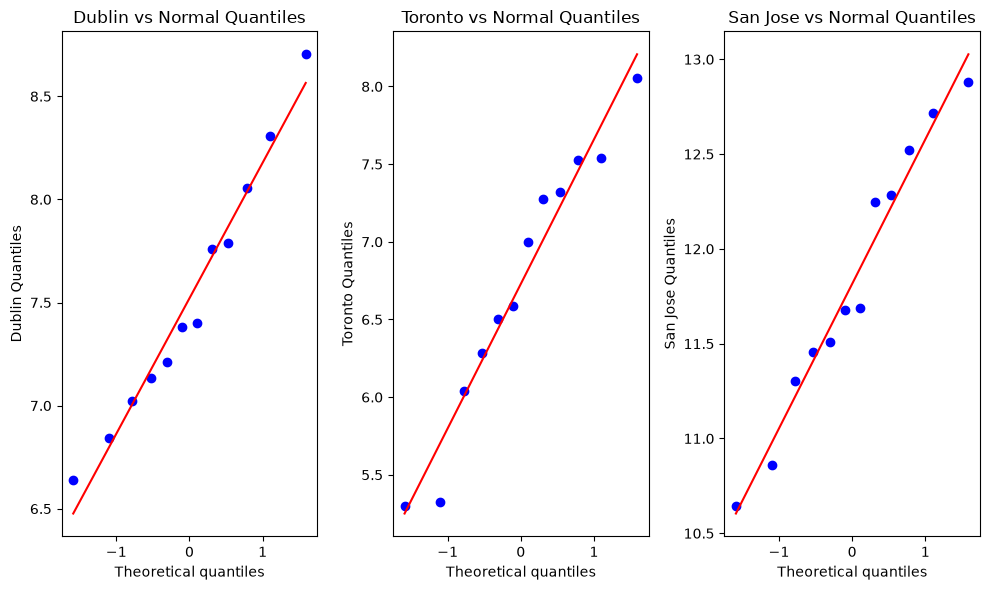

In [4]:
#QQ-plots: Test for normality
years = list(range(2014,2026)) #from 2014-2025
dublin = yearly_avg(weather,'Dublin',years,'Fall')
toronto = yearly_avg(weather,'Toronto',years,'Fall')
sj = yearly_avg(weather,'San Jose',years,'Fall')

fig, axes = plt.subplots(1,3,figsize=(10,6))
stats.probplot(dublin,dist="norm", plot=axes[0])
axes[0].set(title='Dublin vs Normal Quantiles',ylabel="Dublin Quantiles")

stats.probplot(toronto,dist="norm", plot=axes[1])
axes[1].set(title='Toronto vs Normal Quantiles', ylabel="Toronto Quantiles")

stats.probplot(sj,dist="norm", plot=axes[2])
axes[2].set(title='San Jose vs Normal Quantiles', ylabel="San Jose Quantiles")

plt.tight_layout()
plt.show()

In [5]:
#Double check with Shapiro-Wilk Test
station_avgs = {
    "Dublin": dublin,
    "Toronto": toronto,
    "San Jose": sj
}

print("Normality tests (Shapiro-Wilk):")
for key in station_avgs.keys():
    data = station_avgs[key]
    stat, p = stats.shapiro(data)
    print(f"{key}: p = {p:.3f}, {'Normal' if p > 0.05 else 'Not normal'}")


Normality tests (Shapiro-Wilk):
Dublin: p = 0.878, Normal
Toronto: p = 0.599, Normal
San Jose: p = 0.749, Normal


**Data is approximately normal.**
- The qq-plots show that points are relatively close to the diagonal line and there are no distinct S shapes or curved patterns
- Similarly, Shapiro-Wilk tests found that p>0.05 for all 3 stations



### Test for Homogeneity of Variance (Levene's Test)

In [7]:
stat, p_lev = stats.levene(dublin,toronto,sj)
print(f"\nLevene's test for homogeneity:")
print(f"p-value: {p_lev:.3f}")
if p_lev > 0.05:
    print("Variances are homogeneous")
else:
    print("Variances are not homogeneous")


Levene's test for homogeneity:
p-value: 0.379
Variances are homogeneous


## Perform One Way ANOVA
- At significance level alpha=0.05

In [8]:
f_stat, p_anova = stats.f_oneway(dublin,toronto,sj)

print(f"One Way Anova Results\nF-stat: {f_stat}\np-value: {p_anova}")

print(f"\nResult: ")
if p_anova < 0.05:
    print("Reject the null.")
    print("There is evidence to support that there is significant difference between groups.")
    print("Mean fall temperature is different for at least 1 station")
else:
    print("Don't reject the null.")
    print("There is not enough evidence to support significant difference between groups.")

One Way Anova Results
F-stat: 161.36475879237895
p-value: 9.16223869634412e-18

Result: 
Reject the null.
There is evidence to support that there is significant difference between groups.
Mean fall temperature is different for at least 1 station


In [9]:
#Post Hoc Test with Tukey HSD
from statsmodels.stats.multicomp import pairwise_tukeyhsd

#change data into long form
avgs_long = pd.melt(pd.DataFrame(station_avgs), var_name = 'Station', value_name='Avg_Yearly_Fall')

tukey = pairwise_tukeyhsd(endog=avgs_long['Avg_Yearly_Fall'], groups=avgs_long['Station'], alpha=0.05)

print("Tukey's HSD Post-hoc Test Results:")
print(tukey)
print(f"Pvalues: {tukey.pvalues}")

Tukey's HSD Post-hoc Test Results:
  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1   group2  meandiff p-adj   lower   upper  reject
--------------------------------------------------------
  Dublin San Jose   4.2945    0.0  3.5469  5.0422   True
  Dublin  Toronto  -0.7918 0.0361 -1.5394 -0.0442   True
San Jose  Toronto  -5.0863    0.0  -5.834 -4.3387   True
--------------------------------------------------------
Pvalues: [1.66533454e-15 3.60568399e-02 0.00000000e+00]


## Post Hoc Test Interpretation
- P-values of less than 0.05 between all groups show that all three stations have statistically significant differences in mean fall temperatures
- 95% CI for estimated mean difference of Dublin and San Jose is [3.5469,5.0422], showing that it's higher in mean temperature
- These results show that San Jose has the highest mean temperature, followed by Toronto, and then Dublin

In [10]:
#ETA squared (Effect Size)
def eta_squared(groups):
    """Calculate eta-squared for one-way ANOVA"""
    all_data = np.concatenate(groups)
    grand_mean = np.mean(all_data)
    
    # Between-group sum of squares
    ss_between = sum([len(g) * (np.mean(g) - grand_mean)**2 for g in groups])
    
    # Total sum of squares
    ss_total = sum([(x - grand_mean)**2 for x in all_data])
    return ss_between / ss_total

fall_eta = eta_squared([dublin,toronto,sj])
if fall_eta < 0.01:
    print(f"Very small effect: {fall_eta}")
elif fall_eta < 0.06:
    print(f"Small effect: {fall_eta}")
elif fall_eta < 0.14:
    print(f"Medium effect: {fall_eta}")
else: 
    print(f"Large effect: {fall_eta}")

Large effect: 0.9072328879985703


### Conclusion
- Data: Mean fall temperature for each station (n=12 for years 2014-2025)
- Assumptions: Normality, Independence, and Homogenity of Variance were met
- One Way ANOVA: p_value = 9.16223869634412e-18 (<0.05, reject the null that population means of fall temperatures were equal) (Statistically Significant)
- Post Hoc Test: p_values < 0.05 for all pairwise groups
- Eta Squared: Large effect (0.9) (Practical Significance)

There is evidence to support that fall mean temperatures differ between San Jose, Dublin, and Toronto. Tukey's HSD further shows that all 3 stations differ, showing that San Jose has the highest mean while Dublin has the lowest. A combination of both statisical and practical significance shows that the differences in mean fall temperature are not by chance and is meaningful. 